# Handwritten Digit Recognition using Deep Learning

## Project Overview

This project uses Deep Learning to recognize handwritten digits from 0 to 9.

The MNIST dataset is used to train a neural network model. The images are processed and given to a Convolutional Neural Network (CNN), which learns patterns from the handwritten digits and predicts the correct digit.

## Objectives

- To understand the basic workflow of Deep Learning.
- To work with the MNIST handwritten digit dataset.
- To preprocess image data.
- To build and train a CNN model.
- To evaluate the performance of the model.
- To predict handwritten digits using the trained model.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import datasets
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

## 2. Loading the MNIST Dataset

The MNIST dataset contains handwritten digit images from 0 to 9.

The dataset is divided into training data and testing data. The training data is used to teach the model, while the testing data is used to evaluate how well the model performs on unseen images.

In [5]:
# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


## 3. Visualizing Sample Images

A few images from the MNIST dataset are displayed below to understand the type of data used for training the model.

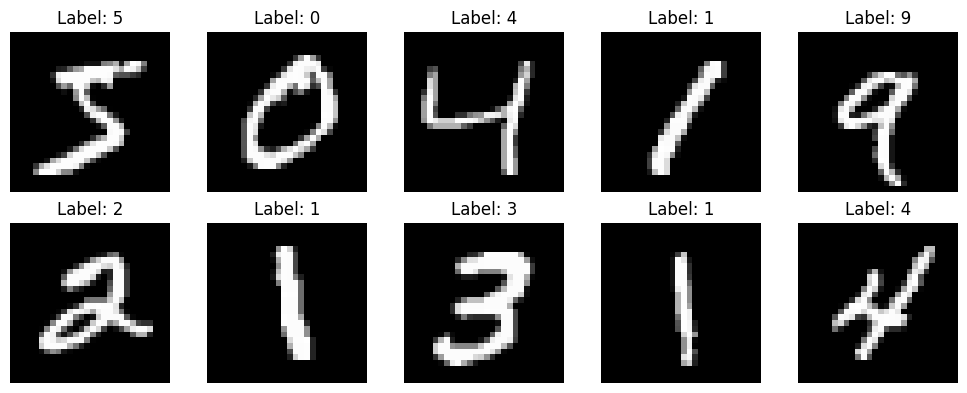

In [6]:
# Display sample images from the dataset

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Preprocessing the Image Data

The pixel values of the MNIST images range from 0 to 255. These values are normalized to a range between 0 and 1 to make the training process more efficient.

The images are also reshaped to include a single grayscale channel, which is required by the CNN model.

In [7]:
# Normalize pixel values to the range 0 to 1

x_train = x_train / 255.0
x_test = x_test / 255.0

# Add a channel dimension for the CNN

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


## 5. Building the Convolutional Neural Network

A Convolutional Neural Network (CNN) is used to recognize patterns in images.

The model contains convolutional layers to detect important image features, pooling layers to reduce the size of the feature maps, and dense layers to classify the digits into 10 classes (0 to 9).

In [8]:
# Build the CNN model

model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compiling the Model

The CNN model is compiled using the Adam optimizer and sparse categorical cross-entropy loss function.

Accuracy is used as the evaluation metric to measure how many test predictions are classified correctly.

In [9]:
# Compile the CNN model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


## 7. Training the Deep Learning Model

The CNN model is trained using the MNIST training dataset.

The model learns patterns from the handwritten digit images over multiple epochs. A validation split is used to monitor the model's performance during training.

In [10]:
# Train the CNN model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.9487 - loss: 0.1686 - val_accuracy: 0.9845 - val_loss: 0.0529
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.9842 - loss: 0.0506 - val_accuracy: 0.9888 - val_loss: 0.0394
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9898 - loss: 0.0326 - val_accuracy: 0.9900 - val_loss: 0.0392
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9926 - loss: 0.0237 - val_accuracy: 0.9915 - val_loss: 0.0338
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9936 - loss: 0.0189 - val_accuracy: 0.9905 - val_loss: 0.0354


## 8. Evaluating the Model

The trained CNN model is evaluated using the MNIST test dataset. The test accuracy shows how well the model performs on images that were not used during training.

In [11]:
# Evaluate the model on test data

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.032
Test Accuracy: 99.01 %


## 9. Training Performance

The training and validation accuracy are plotted to observe how the model's performance changed during training.

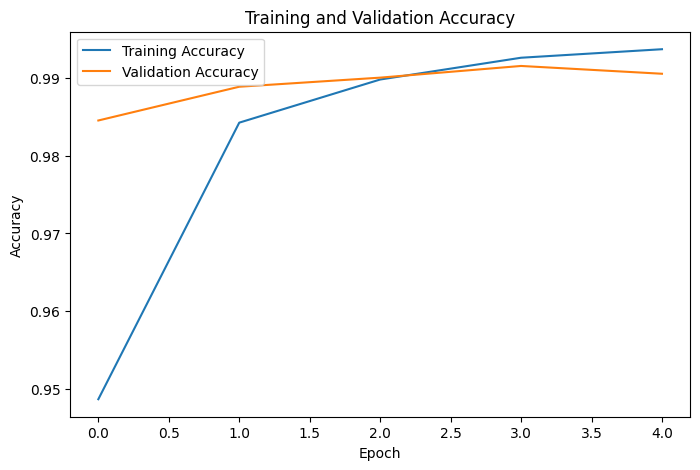

In [12]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.show()

### Training and Validation Loss

The loss graph shows how the prediction error changed during the training process.

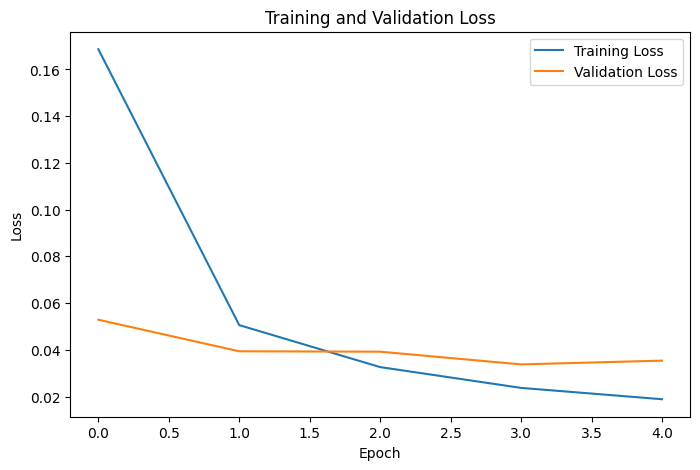

In [13]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

## 10. Predicting Handwritten Digits

The trained CNN model is used to predict digits from the test dataset. The predicted digit is compared with the actual label to check whether the model recognizes the handwritten digit correctly.

In [14]:
# Make predictions on test images

predictions = model.predict(x_test[:10], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", predicted_labels)

Actual labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]


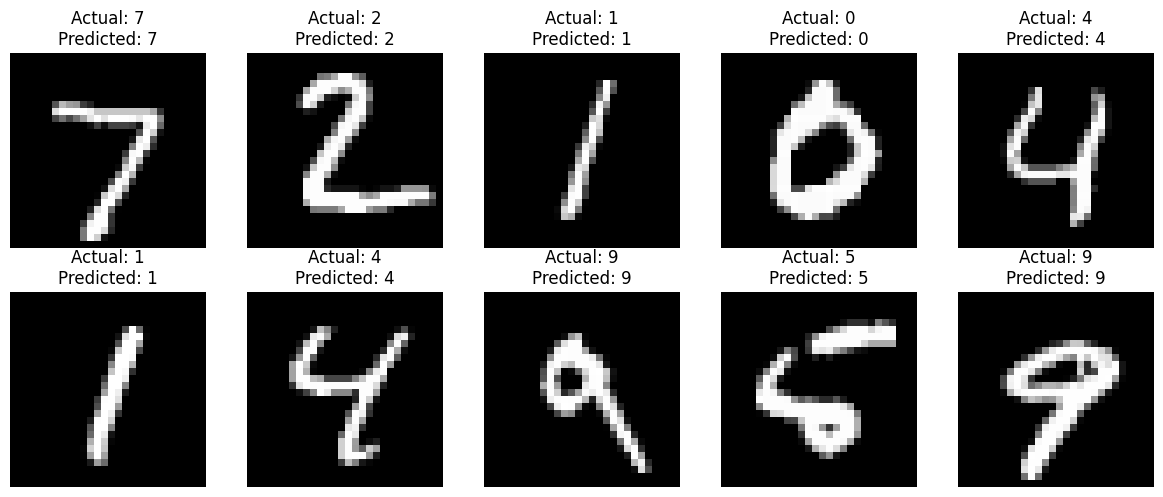

In [15]:
# Display test images with predictions

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 11. Conclusion

This project demonstrates how Deep Learning can be used to recognize handwritten digits using the MNIST dataset. A Convolutional Neural Network (CNN) was trained to classify images into digits from 0 to 9.

The model achieved a test accuracy of 99.01%, showing that the CNN was able to recognize most handwritten digits correctly. The prediction results also demonstrate the practical use of the trained model on unseen images.

This project helped in understanding the basic workflow of a Deep Learning project, including data loading, preprocessing, CNN model building, training, evaluation, and prediction.